In [1]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l


In [2]:
num_input = 200
n_train, n_test = 20,200
batch_size = 5
true_w,true_b = torch.ones((num_input,1))*0.01 , 0.05;
train_data = d2l.synthetic_data(true_w, true_b, n_train)
train_iter = d2l.load_array(train_data, batch_size)
test_data = d2l.synthetic_data(true_w, true_b, n_test)

test_iter = d2l.load_array(test_data, batch_size,is_train=False)


In [28]:
def evaluate_loss(net,data_iter,loss):
    metric = d2l.Accumulator(2)
    for X,y in data_iter:
        y_hat = net(X)
        y = y.reshape(y_hat.shape)
        l = loss(y_hat,y)
        metric.add(l.sum(),y.numel())

    return metric[0]/metric[1]
    
def train(train_iter,test_iter,num_epochs,lr,lambd):
    net = nn.Sequential(nn.Linear(num_input,1))
    for param in net.parameters():
        param.data.normal_(0,0.01)
    loss = nn.MSELoss(reduction='none')
    animator = d2l.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                            xlim=[5, num_epochs], legend=['train', 'test'])
    trainer = torch.optim.SGD([{"params":net[0].weight,"weight_decay":lambd},{"params":net[0].bias}],lr=lr)
    for epoch in range(num_epochs):
        for X,y in train_iter:
            trainer.zero_grad()
            l = loss(net(X),y)
            l.mean().backward()
            trainer.step()
        if epoch==0 or (epoch+1)%5==0:
            animator.add(epoch+1,(evaluate_loss(net,train_iter,loss),evaluate_loss(net,test_iter,loss)))




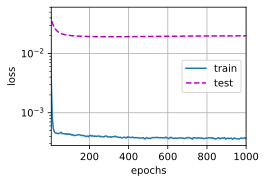

In [30]:
train(train_iter,test_iter, 100, 0.003,lambd=3)